# Module 1: Data Exploration, Wrangling, and Cleaning Focus Areas: EDA, Null Imputation, Outlier Detection 
### ● Data Inspection & Understanding. 
### ● Null Value Imputation
### ● Outlier Detection and Removal
### ● Initial Analysis

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("marriage_proposal.csv")

print("Dataset loaded successfully")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully
Shape: (10000, 9)


,Height,Age,Income,RomanticGestureScore,CompatibilityScore,CommunicationScore,DistanceKM,Response,AgeCategory
0,157,23,9813,10,`,10,81,1,Young
1,141,80,9543,0,9,3,14,1,Senior
2,143,56,43513,4,2,2,55,0,Middle-aged
3,184,18,26317,2,6,9,47,0,Young
4,151,31,6757,7,0,8,81,1,Young


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Number of rows: 10000
Number of columns: 9

Column Names:
['Height', 'Age', 'Income', 'RomanticGestureScore', 'CompatibilityScore', 'CommunicationScore', 'DistanceKM', 'Response', 'AgeCategory']

Data Types:
Height                  int64
Age                     int64
Income                  int64
RomanticGestureScore    int64
CompatibilityScore        str
CommunicationScore      int64
DistanceKM              int64
Response                int64
AgeCategory               str
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Height                10000 non-null  int64
 1   Age                   10000 non-null  int64
 2   Income                10000 non-null  int64
 3   RomanticGestureScore  10000 non-null  int64
 4   CompatibilityScore    10000 non-null  str  
 5   CommunicationScore    10000 non-null  int6

In [4]:
missing = df.isnull().sum()

print("Missing values in each column:")
print(missing)

print("\nMissing percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))

Missing values in each column:
Height                  0
Age                     0
Income                  0
RomanticGestureScore    0
CompatibilityScore      0
CommunicationScore      0
DistanceKM              0
Response                0
AgeCategory             0
dtype: int64

Missing percentage:
Height                  0.0
Age                     0.0
Income                  0.0
RomanticGestureScore    0.0
CompatibilityScore      0.0
CommunicationScore      0.0
DistanceKM              0.0
Response                0.0
AgeCategory             0.0
dtype: float64


In [5]:
print("Unique CompatibilityScore values:")
print(df["CompatibilityScore"].value_counts(dropna=False).sort_index())

Unique CompatibilityScore values:
CompatibilityScore
0     901
1     909
10    909
2     899
3     946
4     907
5     914
6     871
7     877
8     934
9     932
`       1
Name: count, dtype: int64


In [6]:
df["CompatibilityScore"] = pd.to_numeric(
    df["CompatibilityScore"],
    errors="coerce"
)

print(df["CompatibilityScore"].isnull().sum())

1


In [7]:
numeric_columns = [
    "Height",
    "Age",
    "Income",
    "RomanticGestureScore",
    "CompatibilityScore",
    "CommunicationScore",
    "DistanceKM"
]

for col in numeric_columns:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

print("Missing values after numerical imputation:")
print(df[numeric_columns].isnull().sum())

Missing values after numerical imputation:
Height                  0
Age                     0
Income                  0
RomanticGestureScore    0
CompatibilityScore      0
CommunicationScore      0
DistanceKM              0
dtype: int64


In [8]:
categorical_columns = ["AgeCategory"]

for col in categorical_columns:
    mode_value = df[col].mode()[0]
    df[col] = df[col].fillna(mode_value)

print("Missing categorical values:")
print(df[categorical_columns].isnull().sum())

Missing categorical values:
AgeCategory    0
dtype: int64


In [9]:
print("Total missing values after cleaning:")
print(df.isnull().sum().sum())

print("\nData types after cleaning:")
print(df.dtypes)

Total missing values after cleaning:
0

Data types after cleaning:
Height                    int64
Age                       int64
Income                    int64
RomanticGestureScore      int64
CompatibilityScore      float64
CommunicationScore        int64
DistanceKM                int64
Response                  int64
AgeCategory                 str
dtype: object


In [10]:
print("Descriptive Statistics:")
display(df.describe())

Descriptive Statistics:


,Height,Age,Income,RomanticGestureScore,CompatibilityScore,CommunicationScore,DistanceKM,Response
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,169.82330,53.888100,27253.685600,5.000600,5.006300,4.974400,50.730300,0.770000
std,17.63324,21.149683,13033.176946,3.169606,3.166743,3.148799,28.848941,0.420854
min,140.00000,18.000000,5003.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,155.00000,35.000000,16089.500000,2.000000,2.000000,2.000000,26.000000,1.000000
50%,170.00000,54.000000,27109.000000,5.000000,5.000000,5.000000,51.000000,1.000000
75%,185.00000,72.000000,38434.750000,8.000000,8.000000,8.000000,76.000000,1.000000
max,200.00000,90.000000,50000.000000,10.000000,10.000000,10.000000,100.000000,1.000000


In [11]:
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    return Q1, Q3, IQR, lower_bound, upper_bound, outliers

In [12]:
continuous_columns = [
    "Height",
    "Age",
    "Income",
    "RomanticGestureScore",
    "CompatibilityScore",
    "CommunicationScore",
    "DistanceKM"
]

for col in continuous_columns:

    Q1, Q3, IQR, lower, upper, outliers = detect_outliers_iqr(
        df, col
    )

    print("\nColumn:", col)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower)
    print("Upper Bound:", upper)
    print("Number of Outliers:", len(outliers))


Column: Height
Q1: 155.0
Q3: 185.0
IQR: 30.0
Lower Bound: 110.0
Upper Bound: 230.0
Number of Outliers: 0

Column: Age
Q1: 35.0
Q3: 72.0
IQR: 37.0
Lower Bound: -20.5
Upper Bound: 127.5
Number of Outliers: 0

Column: Income
Q1: 16089.5
Q3: 38434.75
IQR: 22345.25
Lower Bound: -17428.375
Upper Bound: 71952.625
Number of Outliers: 0

Column: RomanticGestureScore
Q1: 2.0
Q3: 8.0
IQR: 6.0
Lower Bound: -7.0
Upper Bound: 17.0
Number of Outliers: 0

Column: CompatibilityScore
Q1: 2.0
Q3: 8.0
IQR: 6.0
Lower Bound: -7.0
Upper Bound: 17.0
Number of Outliers: 0

Column: CommunicationScore
Q1: 2.0
Q3: 8.0
IQR: 6.0
Lower Bound: -7.0
Upper Bound: 17.0
Number of Outliers: 0

Column: DistanceKM
Q1: 26.0
Q3: 76.0
IQR: 50.0
Lower Bound: -49.0
Upper Bound: 151.0
Number of Outliers: 0


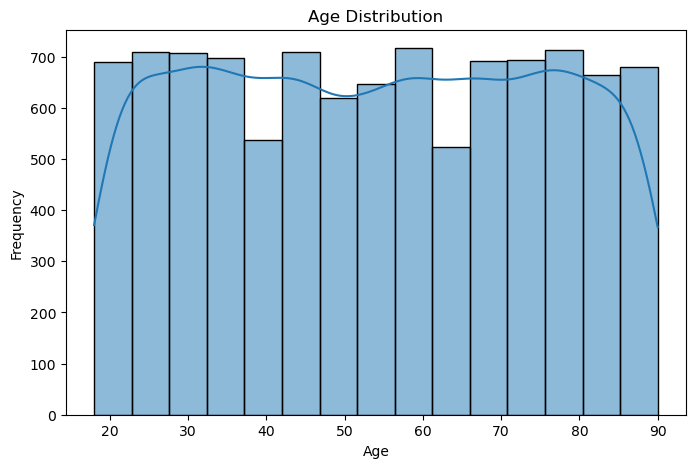

In [13]:
plt.figure(figsize=(8,5))

sns.histplot(df["Age"], bins=15, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

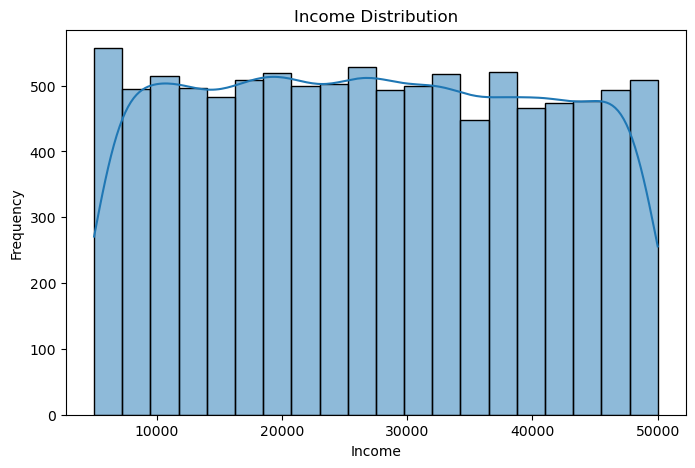

In [14]:
plt.figure(figsize=(8,5))

sns.histplot(df["Income"], bins=20, kde=True)

plt.title("Income Distribution")
plt.xlabel("Income")
plt.ylabel("Frequency")

plt.show()

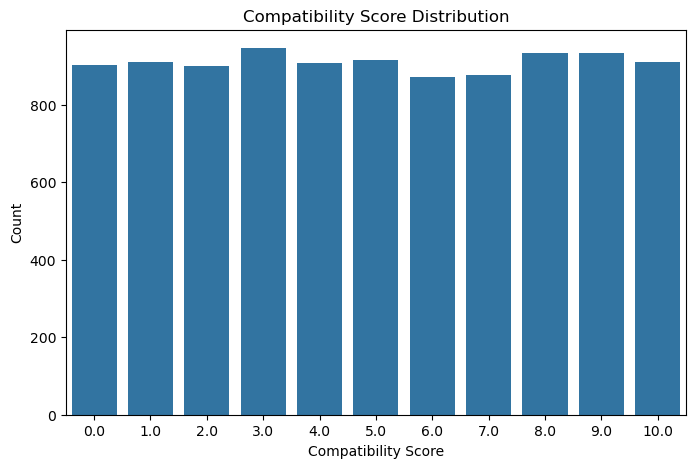

In [15]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="CompatibilityScore"
)

plt.title("Compatibility Score Distribution")
plt.xlabel("Compatibility Score")
plt.ylabel("Count")

plt.show()

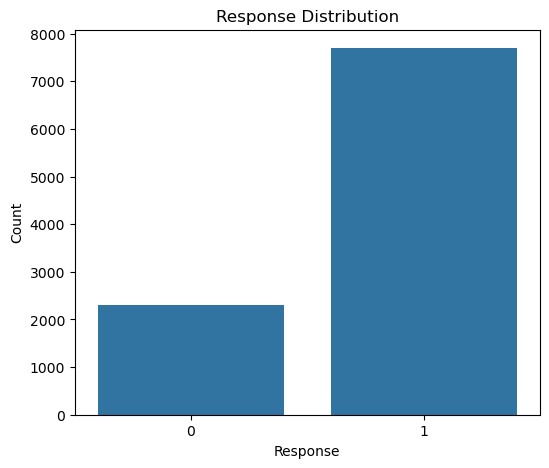

In [16]:
plt.figure(figsize=(6,5))

sns.countplot(
    data=df,
    x="Response"
)

plt.title("Response Distribution")
plt.xlabel("Response")
plt.ylabel("Count")

plt.show()

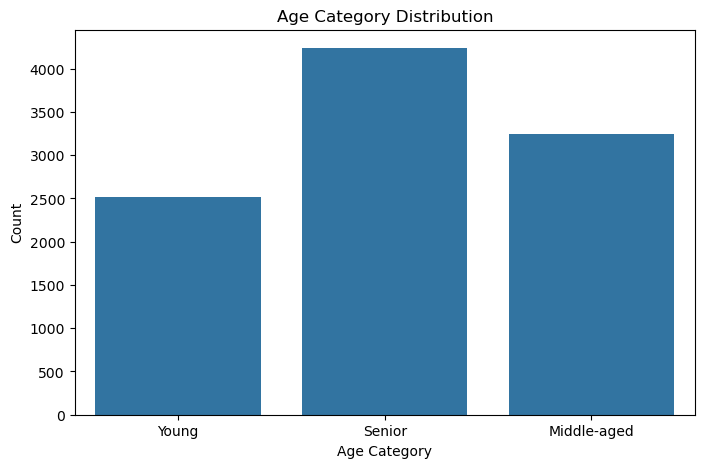

In [17]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="AgeCategory"
)

plt.title("Age Category Distribution")
plt.xlabel("Age Category")
plt.ylabel("Count")

plt.show()

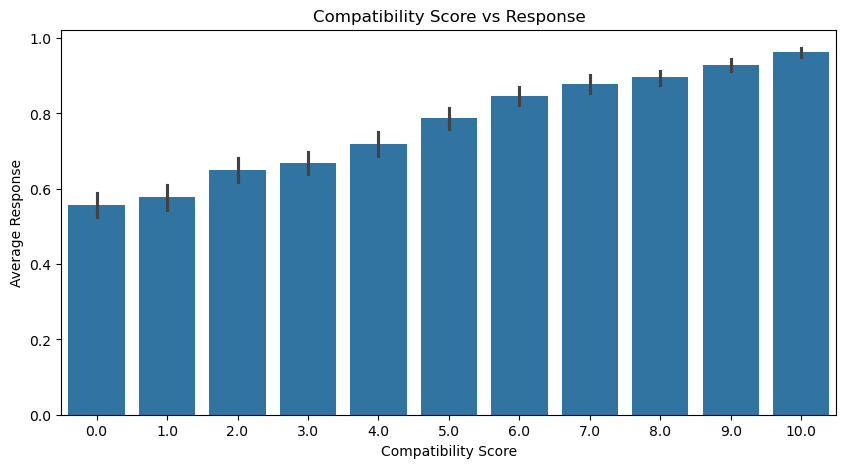

In [18]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=df,
    x="CompatibilityScore",
    y="Response"
)

plt.title("Compatibility Score vs Response")
plt.xlabel("Compatibility Score")
plt.ylabel("Average Response")

plt.show()

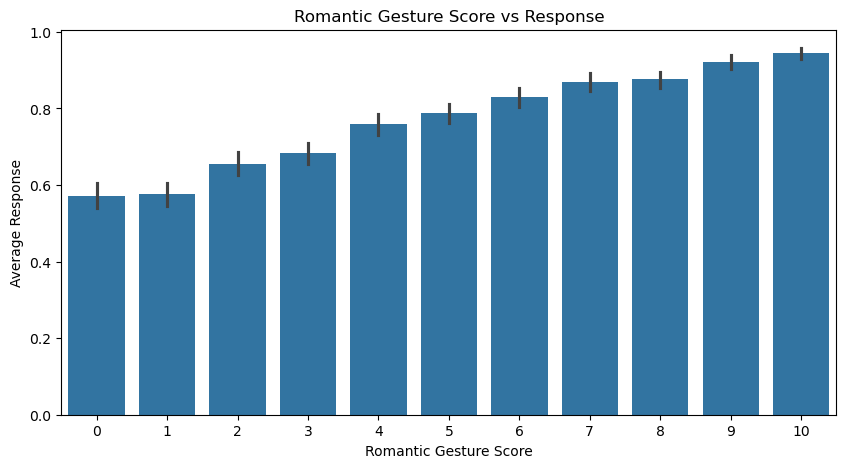

In [19]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=df,
    x="RomanticGestureScore",
    y="Response"
)

plt.title("Romantic Gesture Score vs Response")
plt.xlabel("Romantic Gesture Score")
plt.ylabel("Average Response")

plt.show()

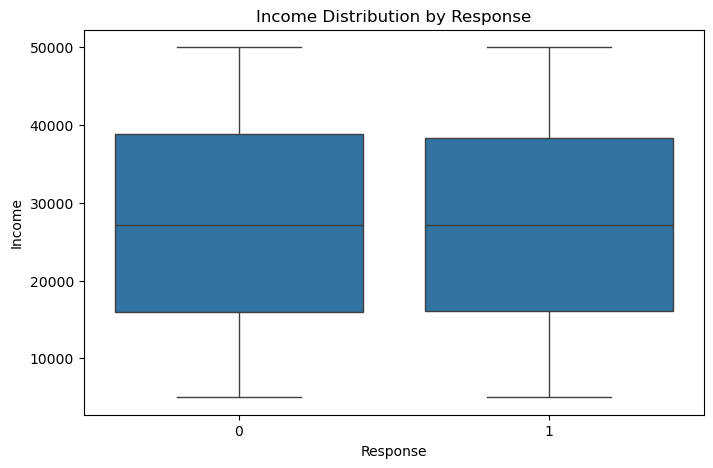

In [20]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Response",
    y="Income"
)

plt.title("Income Distribution by Response")
plt.xlabel("Response")
plt.ylabel("Income")

plt.show()

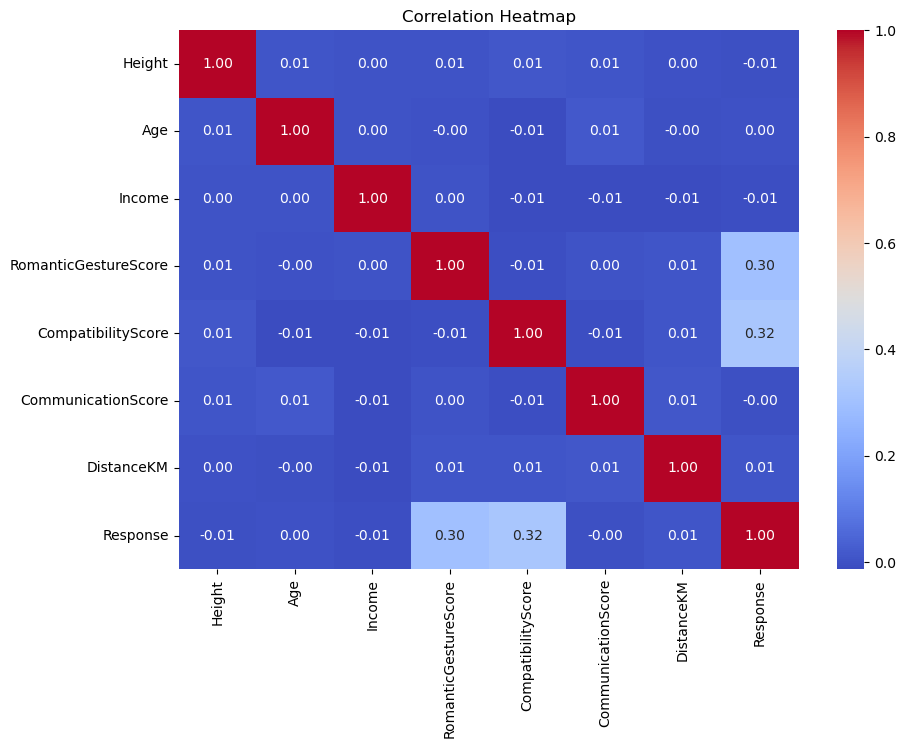

In [21]:
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(10,7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [22]:
age_response = (
    df.groupby("AgeCategory")["Response"]
      .agg(["count", "mean"])
)

print(age_response)

             count      mean
AgeCategory                 
Middle-aged   3243  0.766574
Senior        4239  0.771172
Young         2518  0.772438


In [23]:
df.to_csv(
    "marriage_proposal_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [24]:
categorical_features = [
    "Location",
    "Gender",
    "Occupation"
]

In [25]:
numeric_features = [
    "Season",
    "Age",
    "Expert_Support_Count",
    "Expert_Support_Index",
    "Expert_Consensus_Index"
]

# Module 2: Feature Engineering, Encoding, and Scaling Focus Areas: Encoding Techniques, Feature Engineering, Feature Scaling 
### ● Categorical Encoding
### ● Feature Engineering
### ● Feature Scaling

In [26]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Load dataset
df = pd.read_csv("mafs.csv")

# ==========================================
# 1. FEATURE ENGINEERING
# ==========================================

expert_cols = [
    "DrPepperSchwartz",
    "DrLoganLevkoff",
    "DrJosephCilona",
    "ChaplainGregEpstein",
    "PastorCalvinRoberson",
    "RachelDeAlto",
    "DrJessicaGriffin",
    "DrVivianaColes"
]

# Number of experts supporting the couple
df["Expert_Support_Count"] = df[expert_cols].sum(axis=1)

# Percentage of experts supporting the couple
df["Expert_Support_Index"] = (
    df["Expert_Support_Count"] / len(expert_cols) * 100
).round(2)

# Expert consensus index
df["Expert_Consensus_Index"] = (
    df[expert_cols].mean(axis=1) * 100
).round(2)

# ==========================================
# 2. ENCODE TARGET
# ==========================================

df["Decision_Encoded"] = df["Decision"].map({
    "No": 0,
    "Yes": 1
})

# ==========================================
# 3. NUMERICAL FEATURES
# ==========================================

numeric_features = [
    "Season",
    "Age",
    "Expert_Support_Count",
    "Expert_Support_Index",
    "Expert_Consensus_Index"
]

# ==========================================
# 4. CATEGORICAL FEATURES
# ==========================================

categorical_features = [
    "Location",
    "Gender",
    "Occupation"
]

# ==========================================
# 5. ONE-HOT ENCODING + STANDARDIZATION
# ==========================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

# Transform features
X = preprocessor.fit_transform(df)

# Get generated feature names
feature_names = preprocessor.get_feature_names_out()

# Create processed DataFrame
X_processed = pd.DataFrame(
    X,
    columns=feature_names
)

# Add target
processed = pd.concat(
    [
        X_processed,
        df[["Decision_Encoded"]].reset_index(drop=True)
    ],
    axis=1
)

# ==========================================
# 6. SAVE PROCESSED DATA
# ==========================================

processed.to_csv(
    "mafs_module2_processed.csv",
    index=False
)

# ==========================================
# 7. DISPLAY RESULTS
# ==========================================

print("Original Dataset Shape:", df.shape)
print("Processed Dataset Shape:", processed.shape)

print("\nEngineered Features:")
print(
    df[
        [
            "Expert_Support_Count",
            "Expert_Support_Index",
            "Expert_Consensus_Index"
        ]
    ].head()
)

print("\nProcessed Dataset:")
print(processed.head())

print("\nProcessed dataset saved successfully!")

Original Dataset Shape: (68, 21)
Processed Dataset Shape: (68, 85)

Engineered Features:
   Expert_Support_Count  Expert_Support_Index  Expert_Consensus_Index
0                     4                  50.0                    50.0
1                     4                  50.0                    50.0
2                     4                  50.0                    50.0
3                     4                  50.0                    50.0
4                     4                  50.0                    50.0

Processed Dataset:
   num__Season  num__Age  num__Expert_Support_Count  \
0    -1.663774 -0.936672                   1.666667   
1    -1.663774  0.324589                   1.666667   
2    -1.663774 -1.251987                   1.666667   
3    -1.663774 -0.936672                   1.666667   
4    -1.663774  0.955220                   1.666667   

   num__Expert_Support_Index  num__Expert_Consensus_Index  \
0                   1.666667                     1.666667   
1                 

# Module 3: Feature Selection and Validation Strategy Focus Areas: Feature Selection Methods, Cross-Validation Techniques 
### ● Feature Selection
### ● Validation Blueprint Setup

In [31]:
# ============================================
# MODULE 3
# Feature Selection & Validation Strategy
# ============================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression


# --------------------------------------------
# 1. Load Dataset
# --------------------------------------------

df = pd.read_csv("marriage_proposal.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())


# --------------------------------------------
# 2. Clean CompatibilityScore
# --------------------------------------------

# Convert invalid '`' value to NaN
df["CompatibilityScore"] = pd.to_numeric(
    df["CompatibilityScore"].replace("`", np.nan),
    errors="coerce"
)


# --------------------------------------------
# 3. Separate Features and Target
# --------------------------------------------

X = df.drop("Response", axis=1)
y = df["Response"]

print("\nTarget Distribution:")
print(y.value_counts())

print("\nTarget Distribution (%):")
print(y.value_counts(normalize=True) * 100)


# --------------------------------------------
# 4. Identify Numerical & Categorical Columns
# --------------------------------------------

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("\nNumerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


# --------------------------------------------
# 5. Preprocessing
# --------------------------------------------

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])


# --------------------------------------------
# 6. Base Model for RFE
# --------------------------------------------

base_model = LogisticRegression(
    max_iter=2000,
    solver="liblinear",
    class_weight="balanced"
)


# --------------------------------------------
# 7. Recursive Feature Elimination
# --------------------------------------------

rfe = RFE(
    estimator=base_model,
    n_features_to_select=10,
    step=1
)


# --------------------------------------------
# 8. Final Pipeline
# --------------------------------------------

model = Pipeline([
    ("preprocessing", preprocessor),
    ("feature_selection", rfe),
    ("classifier", LogisticRegression(
        max_iter=2000,
        solver="liblinear",
        class_weight="balanced"
    ))
])


# --------------------------------------------
# 9. Stratified K-Fold Cross Validation
# --------------------------------------------

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# --------------------------------------------
# 10. Evaluation Metrics
# --------------------------------------------

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}


# --------------------------------------------
# 11. Cross Validation
# --------------------------------------------

cv_results = cross_validate(
    model,
    X,
    y,
    cv=skf,
    scoring=scoring,
    return_train_score=False
)


# --------------------------------------------
# 12. Display Results
# --------------------------------------------

print("\n======================================")
print("STRATIFIED 5-FOLD CROSS VALIDATION")
print("======================================")

for metric in scoring.keys():

    scores = cv_results["test_" + metric]

    print(
        f"{metric.upper():10s}: "
        f"{scores.mean():.4f} "
        f"+/- {scores.std():.4f}"
    )


# --------------------------------------------
# 13. Fit Final Model
# --------------------------------------------

model.fit(X, y)


# --------------------------------------------
# 14. Display Selected Features
# --------------------------------------------

feature_names = (
    model
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

selected_features = feature_names[
    model.named_steps["feature_selection"].support_
]

print("\n======================================")
print("SELECTED FEATURES USING RFE")
print("======================================")

for i, feature in enumerate(selected_features, 1):
    print(i, ".", feature)


# --------------------------------------------
# 15. Display Feature Ranking
# --------------------------------------------

ranking = model.named_steps["feature_selection"].ranking_

feature_ranking = pd.DataFrame({
    "Feature": feature_names,
    "Rank": ranking
})

feature_ranking = feature_ranking.sort_values("Rank")

print("\n======================================")
print("FEATURE RANKING")
print("======================================")

print(feature_ranking.to_string(index=False))

Dataset Shape: (10000, 9)

Columns:
['Height', 'Age', 'Income', 'RomanticGestureScore', 'CompatibilityScore', 'CommunicationScore', 'DistanceKM', 'Response', 'AgeCategory']

Target Distribution:
Response
1    7700
0    2300
Name: count, dtype: int64

Target Distribution (%):
Response
1    77.0
0    23.0
Name: proportion, dtype: float64

Numerical Features:
['Height', 'Age', 'Income', 'RomanticGestureScore', 'CompatibilityScore', 'CommunicationScore', 'DistanceKM']

Categorical Features:
['AgeCategory']

STRATIFIED 5-FOLD CROSS VALIDATION
ACCURACY  : 0.7198 +/- 0.0069
PRECISION : 0.8969 +/- 0.0050
RECALL    : 0.7187 +/- 0.0087
F1        : 0.7980 +/- 0.0058
ROC_AUC   : 0.8032 +/- 0.0071

SELECTED FEATURES USING RFE
1 . num__Height
2 . num__Age
3 . num__Income
4 . num__RomanticGestureScore
5 . num__CompatibilityScore
6 . num__CommunicationScore
7 . num__DistanceKM
8 . cat__AgeCategory_Middle-aged
9 . cat__AgeCategory_Senior
10 . cat__AgeCategory_Young

FEATURE RANKING
                    

# Module 4: Model Tuning and Baseline Algorithms Focus Areas: Hyperparameter Tuning, Regression & Classification Algorithms 
### ● Hyperparameter Search
### ● Baseline Modeling 

In [33]:
# ============================================================
# MODULE 4: MODEL TUNING AND BASELINE ALGORITHMS
# Dataset: mafs.csv
# Target: Decision
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer

# Baseline models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Primary model
from sklearn.ensemble import RandomForestClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# STEP 1: Load Dataset
# ------------------------------------------------------------

df = pd.read_csv("mafs.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nTarget Distribution:")
print(df["Decision"].value_counts())

# ------------------------------------------------------------
# STEP 2: Define Target and Features
# ------------------------------------------------------------

target = "Decision"

# Remove identifier columns and post-outcome information
drop_columns = [
    "Decision",
    "Name",
    "Couple",
    "Status"
]

X = df.drop(columns=drop_columns)

# Convert target to numerical format
y = df["Decision"].map({
    "No": 0,
    "Yes": 1
})

print("\nFeatures used for modeling:")
print(X.columns.tolist())

# ------------------------------------------------------------
# STEP 3: Identify Numerical and Categorical Features
# ------------------------------------------------------------

categorical_features = X.select_dtypes(
    include=['object','string']
).columns.tolist()

numerical_features = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("\nCategorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

# ------------------------------------------------------------
# STEP 4: Preprocessing
# ------------------------------------------------------------

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# ------------------------------------------------------------
# STEP 5: Train-Test Split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# ------------------------------------------------------------
# STEP 6: Define Baseline Models
# ------------------------------------------------------------

baseline_models = {

    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(
            max_depth=4,
            min_samples_leaf=2,
            random_state=42
        ))
    ]),

    "K-Nearest Neighbors": Pipeline([
        ("preprocessor", preprocessor),
        ("model", KNeighborsClassifier(
            n_neighbors=5
        ))
    ])
}

# ------------------------------------------------------------
# STEP 7: Train Baseline Models
# ------------------------------------------------------------

results = []

for name, model in baseline_models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test,
        predictions,
        zero_division=0
    )
    recall = recall_score(
        y_test,
        predictions,
        zero_division=0
    )
    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

# ------------------------------------------------------------
# STEP 8: Display Baseline Results
# ------------------------------------------------------------

baseline_results = pd.DataFrame(results)

print("\n================ BASELINE RESULTS ================")
print(baseline_results.round(3))

# ------------------------------------------------------------
# STEP 9: Primary Model - Random Forest
# ------------------------------------------------------------

random_forest = Pipeline([
    ("preprocessor", preprocessor),

    ("model", RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# ------------------------------------------------------------
# STEP 10: Hyperparameter Search Space
# ------------------------------------------------------------

param_distributions = {

    "model__n_estimators": [
        100,
        200,
        300,
        500
    ],

    "model__max_depth": [
        None,
        3,
        5,
        7,
        10
    ],

    "model__min_samples_split": [
        2,
        4,
        6,
        8
    ],

    "model__min_samples_leaf": [
        1,
        2,
        3,
        4
    ],

    "model__max_features": [
        "sqrt",
        "log2",
        None
    ]
}

# ------------------------------------------------------------
# STEP 11: Stratified K-Fold Cross Validation
# ------------------------------------------------------------

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# STEP 12: RandomizedSearchCV
# ------------------------------------------------------------

random_search = RandomizedSearchCV(
    estimator=random_forest,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="f1",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    return_train_score=False
)

# ------------------------------------------------------------
# STEP 13: Run Hyperparameter Tuning
# ------------------------------------------------------------

random_search.fit(
    X_train,
    y_train
)

print("\n================ BEST PARAMETERS ================")

print(random_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(random_search.best_score_, 4))

# ------------------------------------------------------------
# STEP 14: Evaluate Tuned Model
# ------------------------------------------------------------

best_model = random_search.best_estimator_

tuned_predictions = best_model.predict(X_test)

tuned_accuracy = accuracy_score(
    y_test,
    tuned_predictions
)

tuned_precision = precision_score(
    y_test,
    tuned_predictions,
    zero_division=0
)

tuned_recall = recall_score(
    y_test,
    tuned_predictions,
    zero_division=0
)

tuned_f1 = f1_score(
    y_test,
    tuned_predictions,
    zero_division=0
)

print("\n================ TUNED RANDOM FOREST ================")

print("Accuracy :", round(tuned_accuracy, 3))
print("Precision:", round(tuned_precision, 3))
print("Recall   :", round(tuned_recall, 3))
print("F1 Score :", round(tuned_f1, 3))

# ------------------------------------------------------------
# STEP 15: Classification Report
# ------------------------------------------------------------

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        tuned_predictions,
        target_names=["No", "Yes"],
        zero_division=0
    )
)

# ------------------------------------------------------------
# STEP 16: Confusion Matrix
# ------------------------------------------------------------

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        tuned_predictions
    )
)

# ------------------------------------------------------------
# STEP 17: Add Tuned Model to Results
# ------------------------------------------------------------

tuned_result = pd.DataFrame([{
    "Model": "Tuned Random Forest",
    "Accuracy": tuned_accuracy,
    "Precision": tuned_precision,
    "Recall": tuned_recall,
    "F1 Score": tuned_f1
}])

all_results = pd.concat(
    [baseline_results, tuned_result],
    ignore_index=True
)

print("\n================ FINAL MODEL COMPARISON ================")

print(
    all_results.round(3).to_string(index=False)
)

Dataset Shape: (68, 17)

Columns:
['Couple', 'Season', 'Location', 'Name', 'Age', 'Gender', 'Occupation', 'Decision', 'Status', 'DrPepperSchwartz', 'DrLoganLevkoff', 'DrJosephCilona', 'ChaplainGregEpstein', 'PastorCalvinRoberson', 'RachelDeAlto', 'DrJessicaGriffin', 'DrVivianaColes']

Target Distribution:
Decision
Yes    48
No     20
Name: count, dtype: int64

Features used for modeling:
['Season', 'Location', 'Age', 'Gender', 'Occupation', 'DrPepperSchwartz', 'DrLoganLevkoff', 'DrJosephCilona', 'ChaplainGregEpstein', 'PastorCalvinRoberson', 'RachelDeAlto', 'DrJessicaGriffin', 'DrVivianaColes']

Categorical Features:
['Location', 'Gender', 'Occupation']

Numerical Features:
['Season', 'Age', 'DrPepperSchwartz', 'DrLoganLevkoff', 'DrJosephCilona', 'ChaplainGregEpstein', 'PastorCalvinRoberson', 'RachelDeAlto', 'DrJessicaGriffin', 'DrVivianaColes']

Training samples: 54
Testing samples: 14

================ BASELINE RESULTS ================
                 Model  Accuracy  Precision  Rec

# Module 5: Ensemble Learning and Final Model Comparison Focus Areas: Bagging, Boosting, Evaluation Metrics 
### ● Ensemble Implementation
### ● Model Comparison
### ● Final Recommendation

In [35]:
# ============================================================
# MODULE 5: ENSEMBLE LEARNING AND FINAL MODEL COMPARISON
# Dataset: mafs.csv
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

# ------------------------------------------------------------
# 1. Load dataset
# ------------------------------------------------------------

df = pd.read_csv("mafs.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# ------------------------------------------------------------
# 2. Define target
# ------------------------------------------------------------

target = "Decision"

# Convert Yes/No into 1/0
y = df[target].map({
    "No": 0,
    "Yes": 1
})

# ------------------------------------------------------------
# 3. Remove leakage / identifier columns
# ------------------------------------------------------------

drop_columns = [
    "Decision",
    "Status",
    "Name",
    "Couple"
]

X = df.drop(columns=drop_columns)

print("\nFeatures used:")
print(X.columns.tolist())

# ------------------------------------------------------------
# 4. Identify numerical and categorical columns
# ------------------------------------------------------------

categorical_features = X.select_dtypes(
    include=['object','string']
).columns.tolist()

numerical_features = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("\nCategorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

# ------------------------------------------------------------
# 5. Preprocessing
# ------------------------------------------------------------

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# ------------------------------------------------------------
# 6. Define models
# ------------------------------------------------------------

models = {

    "Logistic Regression":
        LogisticRegression(max_iter=2000),

    "Decision Tree":
        DecisionTreeClassifier(
            max_depth=4,
            random_state=42
        ),

    "KNN":
        KNeighborsClassifier(
            n_neighbors=5
        ),

    # BAGGING
    "Random Forest":
        RandomForestClassifier(
            n_estimators=300,
            max_depth=5,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42
        ),

    # BOOSTING
    "AdaBoost":
        AdaBoostClassifier(
            n_estimators=150,
            learning_rate=0.5,
            random_state=42
        ),

    # BOOSTING
    "Gradient Boosting":
        GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=2,
            random_state=42
        )
}

# ------------------------------------------------------------
# 7. Stratified K-Fold Cross Validation
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for model_name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    scores = cross_val_score(
        pipeline,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    results.append({
        "Model": model_name,
        "Fold 1": scores[0],
        "Fold 2": scores[1],
        "Fold 3": scores[2],
        "Fold 4": scores[3],
        "Fold 5": scores[4],
        "Mean Accuracy": scores.mean(),
        "Std Dev": scores.std()
    })

# ------------------------------------------------------------
# 8. Create comparison table
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Mean Accuracy",
    ascending=False
)

print("\n==============================================")
print("MODEL COMPARISON")
print("==============================================")

print(
    results_df.to_string(index=False)
)

# ------------------------------------------------------------
# 9. Convert accuracy into percentage
# ------------------------------------------------------------

display_df = results_df.copy()

display_df["Mean Accuracy"] = (
    display_df["Mean Accuracy"] * 100
).round(2)

display_df["Std Dev"] = (
    display_df["Std Dev"] * 100
).round(2)

for col in ["Fold 1", "Fold 2", "Fold 3", "Fold 4", "Fold 5"]:
    display_df[col] = (
        display_df[col] * 100
    ).round(2)

print("\n==============================================")
print("ACCURACY PERCENTAGES")
print("==============================================")

print(display_df.to_string(index=False))

# ------------------------------------------------------------
# 10. Identify highest-performing model
# ------------------------------------------------------------

best_model_name = results_df.iloc[0]["Model"]
best_accuracy = results_df.iloc[0]["Mean Accuracy"]
best_std = results_df.iloc[0]["Std Dev"]

print("\n==============================================")
print("FINAL MODEL")
print("==============================================")

print("Selected Model:", best_model_name)
print("Mean CV Accuracy:", round(best_accuracy * 100, 2), "%")
print("Standard Deviation:", round(best_std * 100, 2), "%")

# ------------------------------------------------------------
# 11. Train final model
# ------------------------------------------------------------

final_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", models[best_model_name])
])

final_model.fit(X, y)

print("\nFinal model trained successfully.")

# ------------------------------------------------------------
# 12. Save comparison results
# ------------------------------------------------------------

results_df.to_csv(
    "module5_model_comparison.csv",
    index=False
)

print("\nComparison saved as:")
print("module5_model_comparison.csv")

Dataset Shape: (68, 17)

Columns:
['Couple', 'Season', 'Location', 'Name', 'Age', 'Gender', 'Occupation', 'Decision', 'Status', 'DrPepperSchwartz', 'DrLoganLevkoff', 'DrJosephCilona', 'ChaplainGregEpstein', 'PastorCalvinRoberson', 'RachelDeAlto', 'DrJessicaGriffin', 'DrVivianaColes']

Features used:
['Season', 'Location', 'Age', 'Gender', 'Occupation', 'DrPepperSchwartz', 'DrLoganLevkoff', 'DrJosephCilona', 'ChaplainGregEpstein', 'PastorCalvinRoberson', 'RachelDeAlto', 'DrJessicaGriffin', 'DrVivianaColes']

Categorical Features:
['Location', 'Gender', 'Occupation']

Numerical Features:
['Season', 'Age', 'DrPepperSchwartz', 'DrLoganLevkoff', 'DrJosephCilona', 'ChaplainGregEpstein', 'PastorCalvinRoberson', 'RachelDeAlto', 'DrJessicaGriffin', 'DrVivianaColes']

MODEL COMPARISON
              Model   Fold 1   Fold 2   Fold 3   Fold 4   Fold 5  Mean Accuracy  Std Dev
  Gradient Boosting 0.714286 0.714286 0.714286 0.615385 0.692308       0.690110 0.038320
Logistic Regression 0.714286 0.57142